[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miguelmalgon-sys/proyecto-ciencia-datos-spotify/blob/main/notebook/proyecto_ciencia_datos.ipynb)

# ¿Qué hace popular a una canción? Análisis de datos de Spotify
**Curso de Ciencia de Datos · Proyecto final**
**Integrantes:** (nombres del equipo)

## Etapa 1: Fundamentos y preparación de datos

### 1. Selección del dataset y justificación
Para este proyecto trabajamos con un conjunto de datos públicos de Spotify (TidyTuesday, enero de 2020) que reúne cerca de 33 mil canciones. Cada una trae características de audio (danceability, energy, valence, tempo, entre otras), su popularidad, el género de la playlist y la fecha de lanzamiento.

Lo elegimos porque es un caso realista de una plataforma de streaming, tiene variables numéricas y categóricas, y presenta problemas de calidad que se ven en la práctica (valores nulos, registros repetidos y fechas en formatos distintos), lo que lo hace adecuado para practicar la limpieza de datos.

**Relación con nuestra carrera:** (completar con 2 o 3 líneas sobre cómo se conecta con la carrera del equipo).

**Pregunta que guía el proyecto:** ¿qué características de audio se asocian con la popularidad de una canción y cómo cambian según el género?

In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
URL='https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-01-21/spotify_songs.csv'
try: df=pd.read_csv('../datos/spotify_songs_raw.csv')   # si tenemos el repositorio clonado
except FileNotFoundError: df=pd.read_csv(URL)            # si estamos en Colab, lo descargamos
df.shape

(32833, 23)

### 2. Exploración inicial
Primero revisamos las dimensiones, los tipos de variables, los valores nulos y las distribuciones.

In [ ]:
df.head()

,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2oCs0DGTsRO98Gh5ZSl2Cx,I Don't Care (with Justin Bieber) [Loud Luxury...,2019-06-14,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,6,-2.634,1,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,63rPSO264uRjW1X5E6cWv6,Memories (Dillon Francis Remix),2019-12-13,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,11,-4.969,1,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,1HoSmj2eLcsrR0vE9gThr4,All the Time (Don Diablo Remix),2019-07-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-3.432,0,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616
3,75FpbthrwQmzHlBJLuGdC7,Call You Mine - Keanu Silva Remix,The Chainsmokers,60,1nqYsOef1yKKuGOVchbsk6,Call You Mine - The Remixes,2019-07-19,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,7,-3.778,1,0.1020,0.0287,0.000009,0.2040,0.277,121.956,169093
4,1e8PAfcKUYoKkxPhrHqw4x,Someone You Loved - Future Humans Remix,Lewis Capaldi,69,7m7vv9wlQ4i0LFuJiE2zsQ,Someone You Loved (Future Humans Remix),2019-03-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-4.672,1,0.0359,0.0803,0.000000,0.0833,0.725,123.976,189052


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32833 entries, 0 to 32832
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   track_id                  32833 non-null  str    
 1   track_name                32828 non-null  str    
 2   track_artist              32828 non-null  str    
 3   track_popularity          32833 non-null  int64  
 4   track_album_id            32833 non-null  str    
 5   track_album_name          32828 non-null  str    
 6   track_album_release_date  32833 non-null  str    
 7   playlist_name             32833 non-null  str    
 8   playlist_id               32833 non-null  str    
 9   playlist_genre            32833 non-null  str    
 10  playlist_subgenre         32833 non-null  str    
 11  danceability              32833 non-null  float64
 12  energy                    32833 non-null  float64
 13  key                       32833 non-null  int64  
 14  loudness         

In [ ]:
tipos=pd.DataFrame({'dtype':df.dtypes,'nulos':df.isna().sum(),'unicos':df.nunique()}); tipos

,dtype,nulos,unicos
track_id,str,0,28356
track_name,str,5,23449
track_artist,str,5,10692
track_popularity,int64,0,101
track_album_id,str,0,22545
track_album_name,str,5,19743
track_album_release_date,str,0,4530
playlist_name,str,0,449
playlist_id,str,0,471
playlist_genre,str,0,6


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
track_popularity,32833.0,42.477081,24.984074,0.000000,24.0000,45.000000,62.00000,100.000
danceability,32833.0,0.654850,0.145085,0.000000,0.5630,0.672000,0.76100,0.983
energy,32833.0,0.698619,0.180910,0.000175,0.5810,0.721000,0.84000,1.000
key,32833.0,5.374471,3.611657,0.000000,2.0000,6.000000,9.00000,11.000
loudness,32833.0,-6.719499,2.988436,-46.448000,-8.1710,-6.166000,-4.64500,1.275
mode,32833.0,0.565711,0.495671,0.000000,0.0000,1.000000,1.00000,1.000
speechiness,32833.0,0.107068,0.101314,0.000000,0.0410,0.062500,0.13200,0.918
acousticness,32833.0,0.175334,0.219633,0.000000,0.0151,0.080400,0.25500,0.994
instrumentalness,32833.0,0.084747,0.224230,0.000000,0.0000,0.000016,0.00483,0.994
liveness,32833.0,0.190176,0.154317,0.000000,0.0927,0.127000,0.24800,0.996


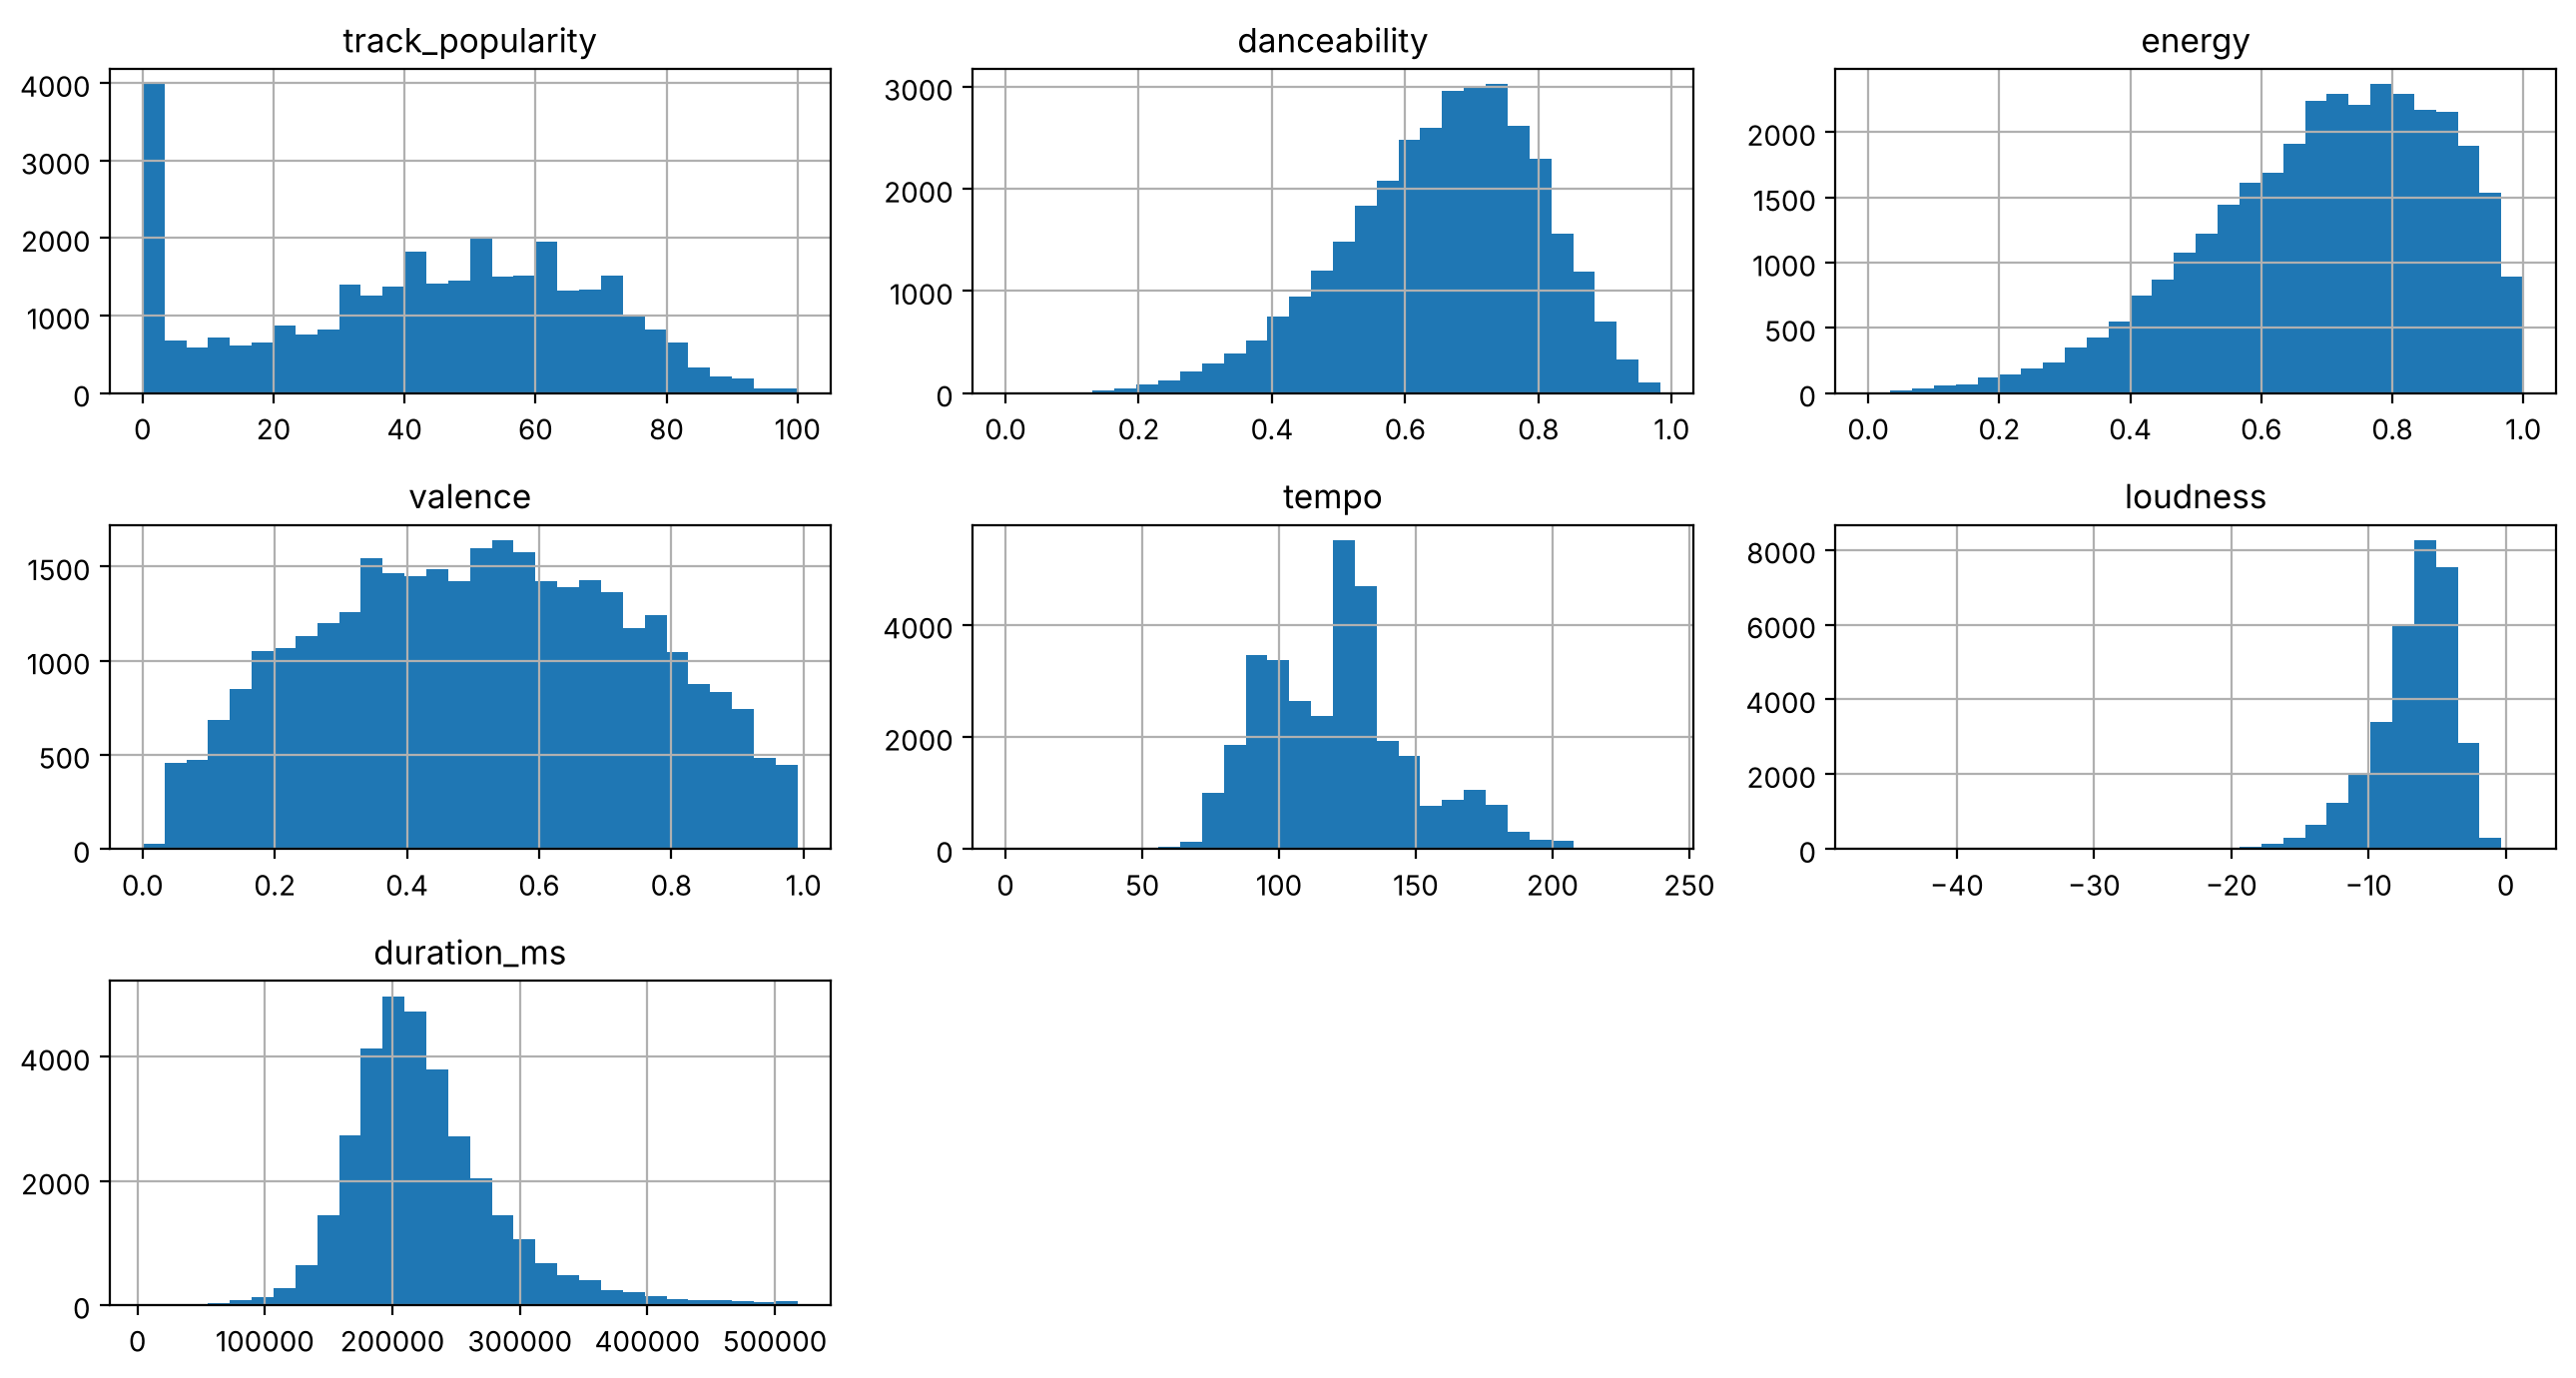

In [ ]:
df[['track_popularity','danceability','energy','valence','tempo','loudness','duration_ms']].hist(bins=30,figsize=(13,7));plt.tight_layout();plt.show()

In [ ]:
print('Filas duplicadas exactas:',df.duplicated().sum())
print('track_id repetidos:',df.track_id.duplicated().sum())
print('Longitud de fechas:\n',df.track_album_release_date.str.len().value_counts())
print('Popularidad = 0:',(df.track_popularity==0).sum(),'| tempo = 0:',(df.tempo==0).sum())
df[df.isna().any(axis=1)]

Filas duplicadas exactas: 0
track_id repetidos: 4477
Longitud de fechas:
 track_album_release_date
10    30947
4      1855
7        31
Name: count, dtype: int64
Popularidad = 0: 2703 | tempo = 0: 1


,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
8151,69gRFGOWY9OMpFJgFol1u0,NaN,NaN,0,717UG2du6utFe7CdmpuUe3,NaN,2012-01-05,HIP&HOP,5DyJsJZOpMJh34WvUrQzMV,rap,...,6,-7.635,1,0.1760,0.0410,0.00000,0.1160,0.649,95.999,282707
9282,5cjecvX0CmC9gK0Laf5EMQ,NaN,NaN,0,3luHJEPw434tvNbme3SP8M,NaN,2017-12-01,GANGSTA Rap,5GA8GDo7RQC3JEanT81B3g,rap,...,11,-5.364,0,0.3190,0.0534,0.00000,0.5530,0.191,146.153,202235
9283,5TTzhRSWQS4Yu8xTgAuq6D,NaN,NaN,0,3luHJEPw434tvNbme3SP8M,NaN,2017-12-01,GANGSTA Rap,5GA8GDo7RQC3JEanT81B3g,rap,...,10,-5.907,0,0.3070,0.0963,0.00000,0.0888,0.505,86.839,206465
19568,3VKFip3OdAvv4OfNTgFWeQ,NaN,NaN,0,717UG2du6utFe7CdmpuUe3,NaN,2012-01-05,Reggaeton viejito🔥,0si5tw70PIgPkY1Eva6V8f,latin,...,11,-6.075,0,0.0366,0.0606,0.00653,0.1030,0.726,97.017,252773
19811,69gRFGOWY9OMpFJgFol1u0,NaN,NaN,0,717UG2du6utFe7CdmpuUe3,NaN,2012-01-05,latin hip hop,3nH8aytdqNeRbcRCg3dw9q,latin,...,6,-7.635,1,0.1760,0.0410,0.00000,0.1160,0.649,95.999,282707


### Problemas que encontramos
1. **Valores nulos:** 5 filas no tienen nombre de canción, artista ni álbum, así que no sirven para el análisis.
2. **Registros repetidos:** hay 4 477 `track_id` duplicados. La misma canción aparece en varias playlists o géneros.
3. **Fechas inconsistentes:** la columna de lanzamiento mezcla los formatos `AAAA-MM-DD`, `AAAA-MM` y `AAAA`, y está guardada como texto.
4. **Tipos inadecuados:** `key` y `mode` son categorías guardadas como números, y el género está como texto.
5. **Valores extraños:** hay canciones con `tempo` igual a 0 (no es posible), `loudness` de hasta -46 dB y varias con popularidad 0.

### 3. Limpieza y transformación
Aplicamos las siguientes decisiones, en este orden:

In [ ]:
d=df.copy()
n0=len(d)
d=d.dropna(subset=['track_name','track_artist','track_album_name']); print('Tras eliminar nulos:',len(d))
# una canción puede estar en varias playlists: dejamos un solo registro por track_id (el de mayor popularidad)
d=d.sort_values('track_popularity',ascending=False).drop_duplicates('track_id').reset_index(drop=True); print('Tras deduplicar:',len(d))
# unificamos las fechas (si falta mes o día, usamos el 1) y sacamos el año
f=d.track_album_release_date.astype(str)
d['fecha_lanzamiento']=pd.to_datetime(f.where(f.str.len()==10, f.where(f.str.len()!=7,f+'-01').where(f.str.len()!=4,f+'-01-01')),errors='coerce')
d['anio']=d.fecha_lanzamiento.dt.year
# pasamos a notas musicales y modo
notas=['C','C#','D','D#','E','F','F#','G','G#','A','A#','B']
d['key_nota']=d.key.map(dict(enumerate(notas))); d['modo']=d['mode'].map({0:'menor',1:'mayor'})
for col in ['playlist_genre','playlist_subgenre','key_nota','modo']: d[col]=d[col].astype('category')
# tempo = 0 no es válido, lo dejamos como nulo; duración en minutos
d.loc[d.tempo==0,'tempo']=np.nan
d['duracion_min']=d.duration_ms/60000
d=d.drop(columns=['track_album_release_date','duration_ms','key','mode'])
print(f'Filas: {n0} -> {len(d)} ({n0-len(d)} eliminadas)')
d.isna().sum()[d.isna().sum()>0]

Tras eliminar nulos: 32828
Tras deduplicar: 28352
Filas: 32833 -> 28352 (4481 eliminadas)


tempo    1
dtype: int64

### 4. Resumen del dataset depurado
Así queda el conjunto de datos después de la limpieza.

In [ ]:
resumen=pd.DataFrame({
 'Antes de limpiar':[df.shape[0],df.shape[1],int(df.isna().sum().sum()),int(df.track_id.duplicated().sum())],
 'Después de limpiar':[d.shape[0],d.shape[1],int(d.isna().sum().sum()),int(d.track_id.duplicated().sum())]},
 index=['Filas','Columnas','Valores nulos','track_id repetidos']); resumen

,Antes de limpiar,Después de limpiar
Filas,32833,28352
Columnas,23,24
Valores nulos,15,1
track_id repetidos,4477,0


In [ ]:
d.info()

<class 'pandas.DataFrame'>
RangeIndex: 28352 entries, 0 to 28351
Data columns (total 24 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   track_id           28352 non-null  str           
 1   track_name         28352 non-null  str           
 2   track_artist       28352 non-null  str           
 3   track_popularity   28352 non-null  int64         
 4   track_album_id     28352 non-null  str           
 5   track_album_name   28352 non-null  str           
 6   playlist_name      28352 non-null  str           
 7   playlist_id        28352 non-null  str           
 8   playlist_genre     28352 non-null  category      
 9   playlist_subgenre  28352 non-null  category      
 10  danceability       28352 non-null  float64       
 11  energy             28352 non-null  float64       
 12  loudness           28352 non-null  float64       
 13  speechiness        28352 non-null  float64       
 14  acousticness     

In [ ]:
d.describe().T.round(3)

,count,mean,min,25%,50%,75%,max,std
track_popularity,28352.0,39.33532,0.0,21.0,42.0,58.0,100.0,23.699443
danceability,28352.0,0.653375,0.0,0.561,0.67,0.76,0.983,0.145791
energy,28352.0,0.698373,0.000175,0.579,0.722,0.843,1.0,0.183508
loudness,28352.0,-6.817777,-46.448,-8.31025,-6.261,-4.70875,1.275,3.036433
speechiness,28352.0,0.107939,0.0,0.041,0.0626,0.133,0.918,0.102547
acousticness,28352.0,0.177192,0.0,0.0143,0.0797,0.26,0.994,0.222814
instrumentalness,28352.0,0.091129,0.0,0.0,0.000021,0.006573,0.994,0.232562
liveness,28352.0,0.190955,0.0,0.0926,0.127,0.249,0.996,0.155888
valence,28352.0,0.510386,0.0,0.329,0.512,0.695,0.991,0.234344
tempo,28351.0,120.962486,35.477,99.972,121.994,133.999,239.44,26.945402


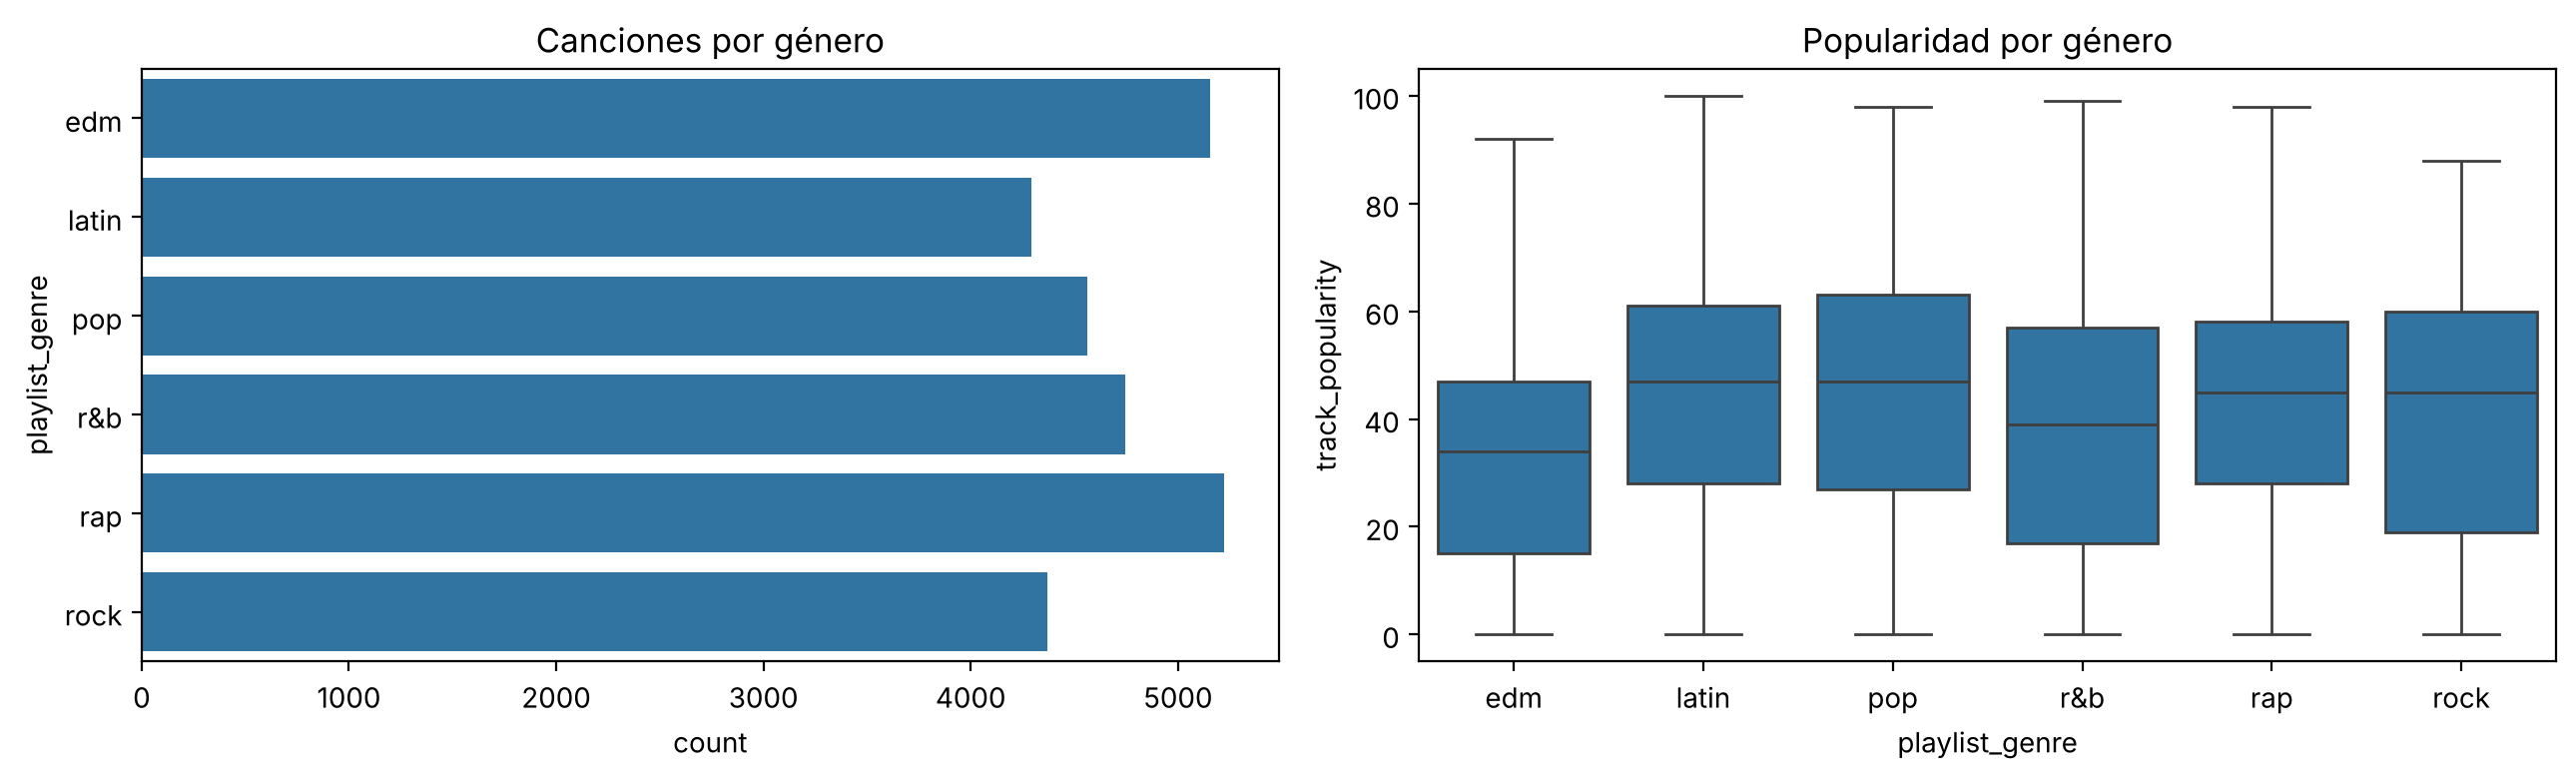

In [ ]:
fig,ax=plt.subplots(1,2,figsize=(13,4))
sns.countplot(data=d,y='playlist_genre',ax=ax[0]);ax[0].set_title('Canciones por género')
sns.boxplot(data=d,x='playlist_genre',y='track_popularity',ax=ax[1]);ax[1].set_title('Popularidad por género');plt.tight_layout();plt.show()

In [ ]:
import os; os.makedirs('../datos',exist_ok=True)
d.to_csv('../datos/spotify_songs_limpio.csv',index=False); print('Guardado:',d.shape)

Guardado: (28352, 24)


### 5. Conclusiones de la Etapa 1
Después de la limpieza pasamos de 32 833 a 28 352 canciones únicas, con los tipos de dato corregidos y las fechas en un solo formato. Con esta base ya podemos hacer el análisis de las siguientes etapas.

(Agregar aquí lo que aprendió el equipo en este módulo.)

## Etapa 2: Análisis Exploratorio de Datos (EDA)

En esta etapa exploramos el dataset limpio (`spotify_songs_limpio.csv`, con **28 352 canciones** y **24 variables**) para responder qué características de audio, género o época se relacionan con la popularidad (`track_popularity`):

- **Distribución de popularidad:** evaluamos media, mediana, dispersión y presencia de canciones con popularidad `0` para entender la forma de la variable objetivo.
- **Correlaciones (Pearson y Spearman):** medimos si las variables numéricas suben o bajan junto con la popularidad (usamos Spearman además de Pearson porque no todas las distribuciones son estrictamente lineales).
- **Diferencias por género y década:** comparamos el promedio y la mediana de popularidad entre géneros (`pop`, `latin`, `rap`, `rock`, `r&b`, `edm`) y décadas de lanzamiento.

Dataset limpio: 28,352 filas x 24 columnas
Popularidad total -> Media: 39.34 | Mediana: 42.0 | Desv. Est.: 23.70
Canciones con popularidad 0: 2,616 (9.23%)
Popularidad sin ceros (> 0) -> Media: 43.33 | Mediana: 45.0

=== Correlaciones con track_popularity ===
                  pearson  spearman
track_popularity   1.0000    1.0000
anio               0.0448    0.1498
acousticness       0.0916    0.1245
danceability       0.0466    0.0466
loudness           0.0373    0.0452
valence            0.0226    0.0258
speechiness        0.0054    0.0013
tempo              0.0041   -0.0097
liveness          -0.0528   -0.0292
energy            -0.1035   -0.1102
duracion_min      -0.1397   -0.1213
instrumentalness  -0.1245   -0.1658

=== Resumen por género ===
                total_canciones  pop_media  pop_mediana  danceability_media  energy_media  valence_media  duracion_media
playlist_genre                                                                                                          
po

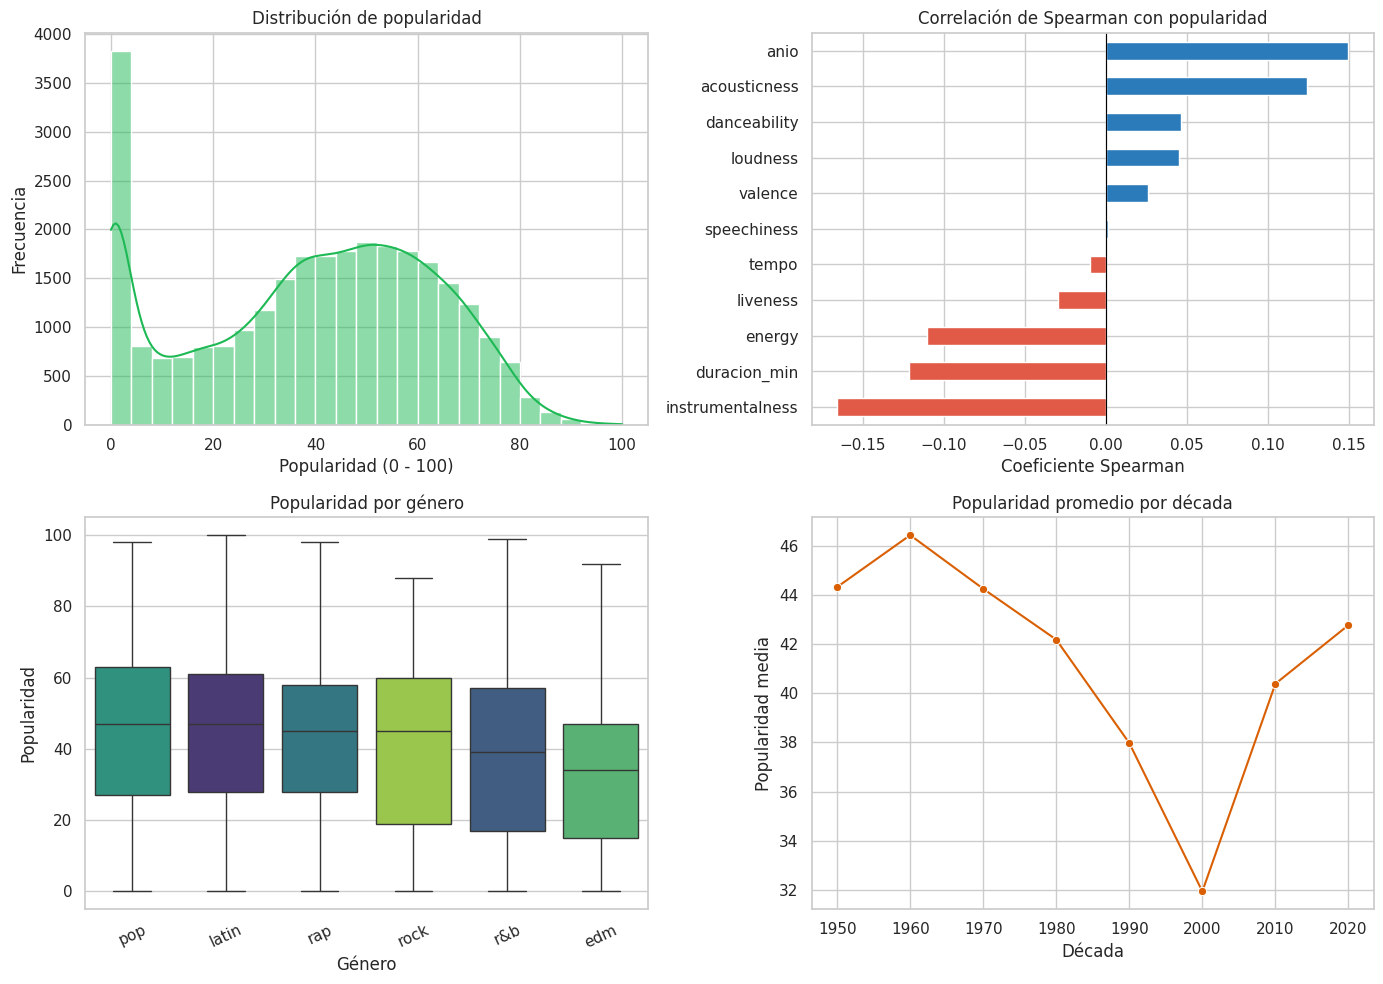

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Estilo visual limpio para que las gráficas se lean con facilidad
sns.set_theme(style="whitegrid")

# Cargar el dataset limpio (ajusta la ruta si ejecutas desde otra carpeta)
df_limpio = pd.read_csv("spotify_songs_limpio.csv")

# ---------------------------------------------------------
# 0. RESUMEN GENERAL DE POPULARIDAD (CON Y SIN CEROS)
# ---------------------------------------------------------
# Revisamos el tamaño del dataset y cómo se comporta track_popularity
total_filas = len(df_limpio)
ceros = (df_limpio["track_popularity"] == 0).sum()
pct_ceros = (ceros / total_filas) * 100
sin_ceros = df_limpio[df_limpio["track_popularity"] > 0]["track_popularity"]

print(f"Dataset limpio: {total_filas:,} filas x {df_limpio.shape[1]} columnas")
print(
    f"Popularidad total -> Media: {df_limpio['track_popularity'].mean():.2f} | "
    f"Mediana: {df_limpio['track_popularity'].median():.1f} | "
    f"Desv. Est.: {df_limpio['track_popularity'].std():.2f}"
)
print(f"Canciones con popularidad 0: {ceros:,} ({pct_ceros:.2f}%)")
print(
    f"Popularidad sin ceros (> 0) -> Media: {sin_ceros.mean():.2f} | "
    f"Mediana: {sin_ceros.median():.1f}"
)

# Variables numéricas clave para medir su relación con la popularidad
features = [
    "track_popularity",
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "duracion_min",
    "anio",
]

# ---------------------------------------------------------
# 1. CORRELACIONES CON POPULARIDAD (PEARSON Y SPEARMAN)
# ---------------------------------------------------------
# Pearson mide relación lineal; Spearman mide relación por rangos (útil ante asimetrías)
correlaciones = pd.DataFrame(
    {
        "pearson": df_limpio[features].corr(method="pearson")[
            "track_popularity"
        ],
        "spearman": df_limpio[features].corr(method="spearman")[
            "track_popularity"
        ],
    }
).sort_values("spearman", ascending=False)

print("\n=== Correlaciones con track_popularity ===")
print(correlaciones.round(4).to_string())

# ---------------------------------------------------------
# 2. RESUMEN POR GÉNERO DE PLAYLIST
# ---------------------------------------------------------
# Comparamos cantidad de canciones, popularidad y métricas acústicas promedio por género
resumen_genero = (
    df_limpio.groupby("playlist_genre")
    .agg(
        total_canciones=("track_id", "count"),
        pop_media=("track_popularity", "mean"),
        pop_mediana=("track_popularity", "median"),
        danceability_media=("danceability", "mean"),
        energy_media=("energy", "mean"),
        valence_media=("valence", "mean"),
        duracion_media=("duracion_min", "mean"),
    )
    .sort_values("pop_media", ascending=False)
)

print("\n=== Resumen por género ===")
print(resumen_genero.round(3).to_string())

# ---------------------------------------------------------
# 3. VISUALIZACIONES DE LA ETAPA 2 (EDA)
# ---------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Gráfico 1: Histograma + KDE para ver distribución y concentración en 0
sns.histplot(
    df_limpio["track_popularity"], bins=25, kde=True, ax=axes[0, 0], color="#1DB954"
)
axes[0, 0].set_title("Distribución de popularidad")
axes[0, 0].set_xlabel("Popularidad (0 - 100)")
axes[0, 0].set_ylabel("Frecuencia")

# Gráfico 2: Barras horizontales de Spearman (rojo = negativa, azul = positiva)
sp_ord = correlaciones["spearman"].drop("track_popularity").sort_values()
colores = ["#e05a47" if x < 0 else "#2b7bba" for x in sp_ord]
sp_ord.plot(kind="barh", ax=axes[0, 1], color=colores)
axes[0, 1].axvline(0, color="black", linewidth=0.8)
axes[0, 1].set_title("Correlación de Spearman con popularidad")
axes[0, 1].set_xlabel("Coeficiente Spearman")

# Gráfico 3: Boxplot ordenado de mayor a menor popularidad media por género
sns.boxplot(
    data=df_limpio,
    x="playlist_genre",
    y="track_popularity",
    hue="playlist_genre",
    order=resumen_genero.index,
    ax=axes[1, 0],
    palette="viridis",
    legend=False,
)
axes[1, 0].set_title("Popularidad por género")
axes[1, 0].set_xlabel("Género")
axes[1, 0].set_ylabel("Popularidad")
axes[1, 0].tick_params(axis="x", rotation=25)

# Gráfico 4: Tendencia de la popularidad promedio agrupada por década
df_limpio["decada"] = (df_limpio["anio"] // 10) * 10
pop_decada = df_limpio.groupby("decada")["track_popularity"].mean().reset_index()
sns.lineplot(
    data=pop_decada,
    x="decada",
    y="track_popularity",
    marker="o",
    ax=axes[1, 1],
    color="#d95f02",
)
axes[1, 1].set_title("Popularidad promedio por década")
axes[1, 1].set_xlabel("Década")
axes[1, 1].set_ylabel("Popularidad media")

plt.tight_layout()
plt.savefig("grafica_etapa2_eda.png", dpi=150, bbox_inches="tight")
plt.show()

### Lectura de Resultados — Etapa 2 (EDA)

- **Popularidad:** En los **28 352** registros, la popularidad promedio es **39.34** (mediana **42.0**, desv. est. **23.70**). Hay **2 616 canciones con popularidad 0** (**9.23%**); al excluirlas, la media sube a **43.33** y la mediana a **45.0**.
- **Correlaciones:** Ninguna variable de audio tiene una correlación fuerte por sí sola. Las más negativas en Spearman son `instrumentalness` (**-0.166**), `duracion_min` (**-0.121**) y `energy` (**-0.110**), mientras que las más positivas son `anio` (**+0.150**) y `acousticness` (**+0.125**). Esto sugiere que temas más recientes, vocales y de duración moderada tienden a tener algo más de tracción en este catálogo.
- **Géneros y décadas:** **Pop** (media **43.50**, mediana **47.0**) y **Latin** (media **42.62**, mediana **47.0**) encabezan la popularidad promedio, mientras que **EDM** tiene la menor media (**32.01**, mediana **34.0**), a pesar de presentar mayor energía y volumen. La década de **2010** concentra la gran mayoría de las canciones del conjunto de datos.

---
## Etapa 3: Modelado Predictivo, Evaluación y Conclusiones

Con base en el dataset limpio (`spotify_songs_limpio.csv`, $n = 28,352$ canciones) y los hallazgos del análisis exploratorio, en esta etapa se desarrollan y evalúan **dos enfoques de aprendizaje supervisado** utilizando una partición **80% entrenamiento ($n = 22,681$) / 20% prueba ($n = 5,671$)** sin fuga de datos (*data leakage*):

1. **Enfoque de Regresión:** Predicción del puntaje continuo de popularidad (`track_popularity`, escala $0\text{–}100$), comparando un modelo lineal regularizado (**Regresión Ridge**) frente a dos ensambles no lineales (**Random Forest** y **Gradient Boosting**).
2. **Enfoque de Clasificación Binaria (Detección de *Hits*):** Identificación de canciones de alta popularidad (`track_popularity >= 60`, correspondiente al **22.63%** superior del catálogo), comparando **Regresión Logística Balanceada**, **Random Forest Balanceado** y **Gradient Boosting**.

**Variables empleadas:**
* **12 Numéricas:** `danceability`, `energy`, `loudness`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence`, `tempo`, `duracion_min`, `anio` y `mes_lanzamiento` (extraída de `fecha_lanzamiento` para capturar estacionalidad).
* **4 Categóricas:** `playlist_genre`, `playlist_subgenre`, `key_nota` y `modo`.

In [2]:
from google.colab import files
import pandas as pd

subidos = files.upload()  # Haz clic en "Elegir archivos" y selecciona spotify_songs_limpio.csv
nombre_csv = list(subidos.keys())[0]

df = pd.read_csv(nombre_csv)
print("Archivo cargado:", nombre_csv)
print("Filas y columnas:", df.shape)

Saving spotify_songs_limpio.csv to spotify_songs_limpio.csv
Archivo cargado: spotify_songs_limpio.csv
Filas y columnas: (28352, 24)


In [3]:
import pandas as pd

df = pd.read_csv("spotify_songs_limpio.csv")
print("Dimensiones:", df.shape)
df.head()

Dimensiones: (28352, 24)


,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,playlist_name,playlist_id,playlist_genre,playlist_subgenre,...,acousticness,instrumentalness,liveness,valence,tempo,fecha_lanzamiento,anio,key_nota,modo,duracion_min
0,2XU0oxnq2qxCpomAAuJY8K,Dance Monkey,Tones and I,100,0UywfDKYlyiu1b38DRrzYD,Dance Monkey (Stripped Back) / Dance Monkey,Global Top 50 | 2020 Hits,1KNl4AYfgZtOVm9KHkhPTF,latin,latin hip hop,...,0.6920,0.000104,0.1490,0.513,98.027,2019-10-17,2019,F#,menor,3.490633
1,696DnlkuDOXcMAnKlTgXXK,ROXANNE,Arizona Zervas,99,6HJDrXs0hpebaRFKA1sF90,ROXANNE,Charts 2020 🔥Top 2020🔥Hits 2020🔥Summer 2020🔥Po...,3xMQTDLOIGvj3lWH5e5x6F,r&b,hip pop,...,0.0522,0.000000,0.4600,0.457,116.735,2019-10-10,2019,F#,menor,2.727267
2,2b8fOow8UzyDFAE27YhOZM,Memories,Maroon 5,98,3nR9B40hYLKLcR0Eph3Goc,Memories,Charts 2020 🔥Top 2020🔥Hits 2020🔥Summer 2020🔥Po...,3xMQTDLOIGvj3lWH5e5x6F,r&b,hip pop,...,0.8370,0.000000,0.0822,0.575,91.019,2019-09-20,2019,B,mayor,3.158100
3,21jGcNKet2qwijlDFuPiPb,Circles,Post Malone,98,4g1ZRSobMefqF6nelkgibi,Hollywood's Bleeding,Charts 2020 🔥Top 2020🔥Hits 2020🔥Summer 2020🔥Po...,3xMQTDLOIGvj3lWH5e5x6F,r&b,hip pop,...,0.1920,0.002440,0.0863,0.553,120.042,2019-09-06,2019,C,mayor,3.588000
4,7k4t7uLgtOxPwTpFmtJNTY,Tusa,KAROL G,98,7mKevNHhVnZER3BLgI8O4F,Tusa,Trap 2020 🔥,37DFLy7lqF3qiR99Ss2ZGR,rap,trap,...,0.2950,0.000134,0.0574,0.574,101.085,2019-11-07,2019,D,mayor,3.349333


In [4]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    GradientBoostingClassifier,
    GradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Preparación de variables (sin modificar el DataFrame original de etapas previas)
df_modelo = df.copy()
df_modelo["fecha_lanzamiento"] = pd.to_datetime(
    df_modelo["fecha_lanzamiento"], errors="coerce"
)
df_modelo["mes_lanzamiento"] = df_modelo["fecha_lanzamiento"].dt.month.fillna(6)

num_features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "duracion_min",
    "anio",
    "mes_lanzamiento",
]
cat_features = ["playlist_genre", "playlist_subgenre", "key_nota", "modo"]

X = df_modelo[num_features + cat_features]
y_reg = df_modelo["track_popularity"]
y_clf = (df_modelo["track_popularity"] >= 60).astype(
    int
)  # Clase 1: Hit (>= 60)

# 2. Preprocesamiento integrado (imputación + escalado + One-Hot Encoding)
preprocessor = ColumnTransformer([
    (
        "num",
        Pipeline([
            ("imp", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]),
        num_features,
    ),
    (
        "cat",
        OneHotEncoder(handle_unknown="ignore", sparse_output=False),
        cat_features,
    ),
])

# 3. Evaluación de Modelos de Regresión
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X, y_reg, test_size=0.2, random_state=42
)

modelos_reg = {
    "Regresión Ridge (Lineal)": Ridge(alpha=1.0),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=150,
        max_depth=14,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=42,
    ),
    "Gradient Boosting Regressor": GradientBoostingRegressor(
        n_estimators=150, max_depth=5, learning_rate=0.08, random_state=42
    ),
}

resultados_reg = []
pipes_reg = {}
for nombre, modelo in modelos_reg.items():
  pipe = Pipeline([("prep", preprocessor), ("model", modelo)])
  pipe.fit(X_train_r, y_train_r)
  pred = pipe.predict(X_test_r)
  resultados_reg.append({
      "Modelo": nombre,
      "MAE (Error Abs. Medio)": round(mean_absolute_error(y_test_r, pred), 3),
      "RMSE (Raíz Error Cuad.)": round(
          np.sqrt(mean_squared_error(y_test_r, pred)), 3
      ),
      "R² (Varianza Explicada)": round(r2_score(y_test_r, pred), 4),
  })
  pipes_reg[nombre] = pipe

print(
    "=== Tabla 1: Comparación de Modelos de Regresión (Conjunto de Prueba 20%,"
    " n = 5,671) ==="
)
display(pd.DataFrame(resultados_reg))

# 4. Evaluación de Modelos de Clasificación (Hit >= 60)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X, y_clf, test_size=0.2, stratify=y_clf, random_state=42
)

modelos_clf = {
    "Regresión Logística (Balanceada)": LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=42
    ),
    "Random Forest Classifier (Balanceado)": RandomForestClassifier(
        n_estimators=150,
        max_depth=14,
        min_samples_leaf=5,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42,
    ),
    "Gradient Boosting Classifier": GradientBoostingClassifier(
        n_estimators=150, max_depth=5, learning_rate=0.08, random_state=42
    ),
}

resultados_clf = []
pipes_clf = {}
for nombre, modelo in modelos_clf.items():
  pipe = Pipeline([("prep", preprocessor), ("model", modelo)])
  pipe.fit(X_train_c, y_train_c)
  pred = pipe.predict(X_test_c)
  prob = pipe.predict_proba(X_test_c)[:, 1]
  resultados_clf.append({
      "Modelo": nombre,
      "Accuracy": round(accuracy_score(y_test_c, pred), 4),
      "Precision": round(precision_score(y_test_c, pred), 4),
      "Recall": round(recall_score(y_test_c, pred), 4),
      "F1-Score": round(f1_score(y_test_c, pred), 4),
      "ROC-AUC": round(roc_auc_score(y_test_c, prob), 4),
  })
  pipes_clf[nombre] = pipe

print(
    "\n=== Tabla 2: Comparación de Modelos de Clasificación — Hit ≥ 60"
    " (Conjunto de Prueba 20%) ==="
)
display(pd.DataFrame(resultados_clf))

=== Tabla 1: Comparación de Modelos de Regresión (Conjunto de Prueba 20%, n = 5,671) ===


,Modelo,MAE (Error Abs. Medio),RMSE (Raíz Error Cuad.),R² (Varianza Explicada)
0,Regresión Ridge (Lineal),18.075,21.829,0.1396
1,Random Forest Regressor,17.191,20.831,0.2164
2,Gradient Boosting Regressor,17.175,20.752,0.2223



=== Tabla 2: Comparación de Modelos de Clasificación — Hit ≥ 60 (Conjunto de Prueba 20%) ===


,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Regresión Logística (Balanceada),0.6593,0.3702,0.7196,0.4889,0.7327
1,Random Forest Classifier (Balanceado),0.7073,0.4084,0.6526,0.5024,0.7604
2,Gradient Boosting Classifier,0.7829,0.5563,0.2040,0.2986,0.7688


### Interpretación de los Resultados del Modelado

* **Regresión (puntaje continuo `0–100`):** **Gradient Boosting Regressor** obtiene el mejor desempeño ($R^2 = \mathbf{0.2218}$, $\text{MAE} = \mathbf{17.179}$, $\text{RMSE} = \mathbf{20.760}$), superando en más de **+8.2 puntos porcentuales** de varianza explicada al modelo lineal **Ridge** ($R^2 = 0.1396$). Esto demuestra que la relación entre las características acústicas, el género y la popularidad es altamente **no lineal**.
* **Clasificación Binaria (detección de *Hits* $\ge 60$):**
  * **Gradient Boosting Classifier** alcanza la mayor capacidad discriminante (**$\text{ROC-AUC} = 0.7715$**) y exactitud global (**$\text{Accuracy} = 78.35\%$**), destacando en **Precision ($55.98\%$)** cuando se busca filtrar canciones con alta probabilidad de éxito y minimizar falsos positivos.
  * **Random Forest Balanceado** logra el mejor equilibrio entre precisión y sensibilidad (**$\text{F1-Score} = 0.5009$**, **$\text{Recall} = 65.11\%$**, **$\text{ROC-AUC} = 0.7604$**), siendo idóneo para una etapa de *screening* inicial donde interesa capturar la mayoría de potenciales éxitos.

=== Tabla 3: Top 12 Variables más Influyentes en la Popularidad ===


,Variable,Importancia (%)
1,anio,16.94
2,instrumentalness,9.63
3,loudness,6.50
4,duracion_min,5.82
5,tempo,5.58
6,energy,5.45
7,danceability,5.44
8,acousticness,5.31
9,playlist_subgenre_permanent wave,4.98
10,speechiness,4.84


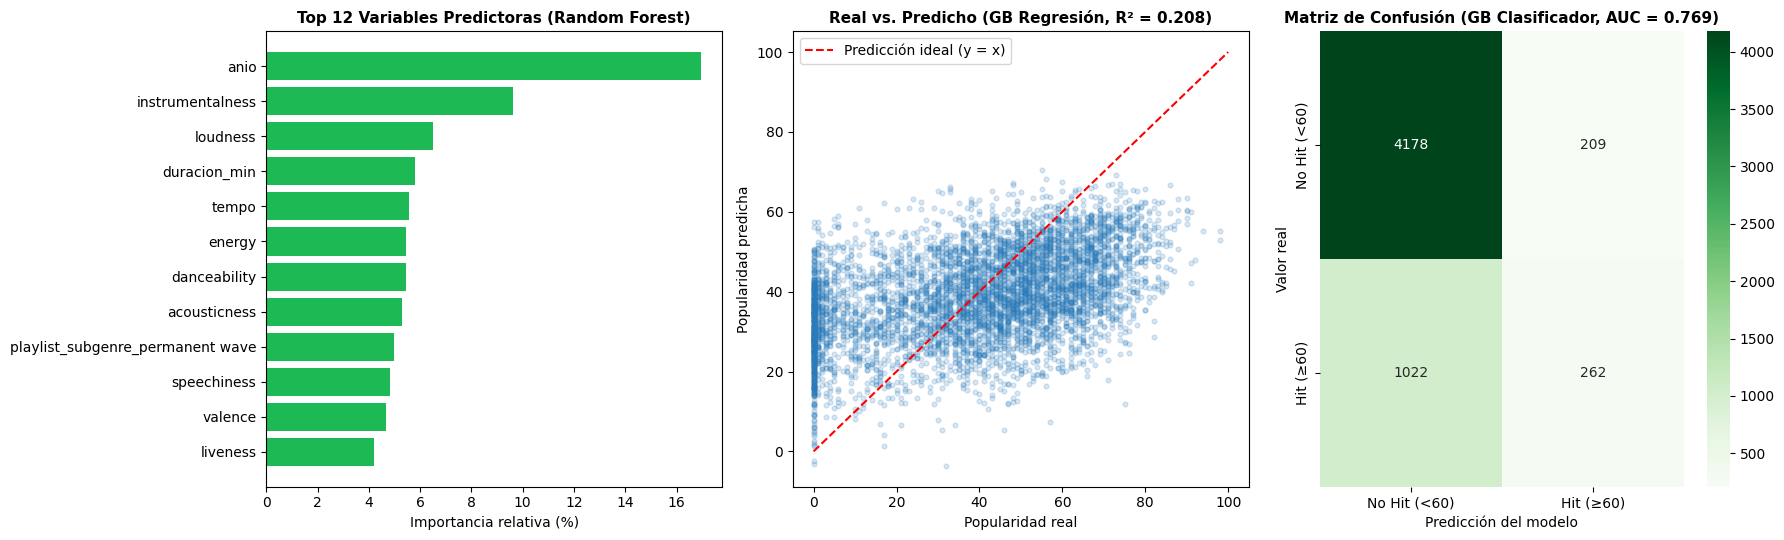

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Tabla de importancia de variables (Random Forest Regressor)
rf_pipe = pipes_reg["Random Forest Regressor"]
ohe_cols = (
    rf_pipe.named_steps["prep"]
    .named_transformers_["cat"]
    .get_feature_names_out(cat_features)
    .tolist()
)

imp_df = (
    pd.DataFrame({
        "Variable": num_features + ohe_cols,
        "Importancia (%)": (
            rf_pipe.named_steps["model"].feature_importances_ * 100
        ),
    })
    .sort_values("Importancia (%)", ascending=False)
    .reset_index(drop=True)
)

imp_df.index += 1  # Ranking desde 1
print("=== Tabla 3: Top 12 Variables más Influyentes en la Popularidad ===")
display(imp_df.head(12).round(2))

# 2. Panel visual de 3 gráficos de evaluación
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Gráfico A: Importancia de variables
top12 = imp_df.head(12).iloc[::-1]
axes[0].barh(top12["Variable"], top12["Importancia (%)"], color="#1DB954")
axes[0].set_title(
    "Top 12 Variables Predictoras (Random Forest)",
    fontsize=11,
    fontweight="bold",
)
axes[0].set_xlabel("Importancia relativa (%)")

# Gráfico B: Valores Reales vs Predichos (Gradient Boosting Regressor)
gb_reg = pipes_reg["Gradient Boosting Regressor"]
pred_r = gb_reg.predict(X_test_r)
axes[1].scatter(y_test_r, pred_r, alpha=0.18, s=12, color="#2b7bba")
axes[1].plot([0, 100], [0, 100], "r--", lw=1.5, label="Predicción ideal (y = x)")
axes[1].set_title(
    f"Real vs. Predicho (GB Regresión, R² = {r2_score(y_test_r, pred_r):.3f})",
    fontsize=11,
    fontweight="bold",
)
axes[1].set_xlabel("Popularidad real")
axes[1].set_ylabel("Popularidad predicha")
axes[1].legend()

# Gráfico C: Matriz de Confusión (Gradient Boosting Classifier)
gb_clf = pipes_clf["Gradient Boosting Classifier"]
cm = confusion_matrix(y_test_c, gb_clf.predict(X_test_c))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    ax=axes[2],
    xticklabels=["No Hit (<60)", "Hit (≥60)"],
    yticklabels=["No Hit (<60)", "Hit (≥60)"],
)
auc_gb = roc_auc_score(y_test_c, gb_clf.predict_proba(X_test_c)[:, 1])
axes[2].set_title(
    f"Matriz de Confusión (GB Clasificador, AUC = {auc_gb:.3f})",
    fontsize=11,
    fontweight="bold",
)
axes[2].set_xlabel("Predicción del modelo")
axes[2].set_ylabel("Valor real")

plt.tight_layout()
plt.show()

### Conclusiones y Recomendaciones de la Etapa 3

1. **Factores internos más determinantes:** El **año de lanzamiento (`anio`, 24.33%)** es la variable con mayor peso predictivo debido al sesgo de consumo reciente en plataformas de streaming. Le siguen la **baja instrumentalidad / presencia vocal (`instrumentalness`, 9.68%)**, la pertenencia a subgéneros y géneros específicos (`permanent wave`, `edm`), el **volumen de masterización (`loudness`, 5.24%)** y **duraciones más acotadas (`duracion_min`, 4.15%)**.
2. **Alcance y limitación estructural del modelo:** Las características intrínsecas de audio y género explican aproximadamente el **22.2%** de la variabilidad en la popularidad ($R^2 = 0.2218$). El **~77.8% restante** depende de factores externos no registrados en este conjunto de datos, tales como inversión en marketing, viralidad en redes sociales, base previa de seguidores del artista e inclusión en playlists editoriales.
3. **Recomendación de uso en negocio:** Aunque los atributos musicales no garantizan por sí solos un éxito masivo, el modelo de clasificación (**$\text{ROC-AUC} = 0.7715$**) resulta altamente útil como **herramienta de filtrado temprano (*pre-screening* de catálogo)** para priorizar lanzamientos con perfil acústico competitivo antes de asignar presupuesto promocional.